In [1]:
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt
import scipy

import pynapple as nap
from neo.rawio import BlackrockRawIO

from utils import load_task_events, label, split_by

In [2]:
# 20231104 is day 2 and consisted of short blocks (20 exposure blocks x 25 sequences with 24% deviant rate, followed by 10 exposure blocks x 25 sequences with 0% deviant rate)

data_day2_path = "../../../Recordings/Silas/Data/20231104"
derivatives_path = "../../derivatives"
figure_path = "../../figures"

data_day2 = nap.EphysReader(f"{data_day2_path}/SeqPre_110423_a001.nev")  # pynapple can load nev files
behav_data_day2_matlab = scipy.io.loadmat(f"{data_day2_path}/Silas_231104_00_bhv/Silas_231104_00_bhv.mat")  # mat73 does not work on this matlab version file

In [3]:
print(behav_data_day2_matlab['bhv'][0][0]['temp_trial'][0][0].dtype.names)
assert np.all(behav_data_day2_matlab['bhv'][0][0]['temp_trial'][0][0]['blockId'][0] == np.concatenate([np.tile(np.repeat([1, 2], 100), 10), np.zeros(1000, dtype=int)]))  # double-check that the blockID = contextID = context label for each of the 3000 trials is as expected

behav_data_day2 = behav_data_day2_matlab['bhv'][0][0]['temp_trial'][0][0][['blockId', 'seq', 'imgId', 'imgTime']]
print(behav_data_day2['seq'][0][0].shape)
print(behav_data_day2['seq'][0][0])

('numBlockPair', 'totalSeqsPerBlock', 'swapRepeats', 'swapRate', 'blockNum', 'cur_blockNum', 'blockId', 'cur_blockId', 'blockStartTime', 'blockEndTime', 'imgNum', 'cur_imgNum', 'imgId', 'imgTime', 'numTestBlocks', 'numTestSeqs', 'initialStartTime', 'seqStartTime', 'seqEndTime', 'seq', 'RewardSt', 'RewardEd', 'Eye')
(1, 25)
[[array([[5, 6, 7, 8]], dtype=uint8) array([[5, 6, 7, 8]], dtype=uint8)
  array([[5, 6, 7, 8]], dtype=uint8) array([[1, 2, 3, 8]], dtype=uint8)
  array([[5, 6, 7, 8]], dtype=uint8) array([[5, 6, 7, 8]], dtype=uint8)
  array([[5, 6, 7, 8]], dtype=uint8) array([[1, 2, 3, 4]], dtype=uint8)
  array([[5, 6, 7, 4]], dtype=uint8) array([[1, 2, 3, 4]], dtype=uint8)
  array([[1, 2, 3, 4]], dtype=uint8) array([[1, 2, 3, 4]], dtype=uint8)
  array([[1, 2, 3, 4]], dtype=uint8) array([[1, 2, 3, 4]], dtype=uint8)
  array([[5, 6, 7, 8]], dtype=uint8) array([[1, 2, 3, 4]], dtype=uint8)
  array([[1, 2, 3, 4]], dtype=uint8) array([[1, 2, 3, 4]], dtype=uint8)
  array([[5, 6, 7, 8]], dty

In [4]:
# import mat73
# tmp = mat73.loadmat(f"{data_day2_path}/SeqPre_110423_a001.mat")
# print(tmp['NEV'])

In [5]:
data_day2

SeqPre_110423_a001
┍━━━━━━━━━━━━━━━━━━━━━━┯━━━━━━━━━━┑
│ Key                  │ Type     │
┝━━━━━━━━━━━━━━━━━━━━━━┿━━━━━━━━━━┥
│ 0:nsx3               │ TsdFrame │
│ 1:nsx4               │ TsdFrame │
│ 2:nsx6               │ TsdFrame │
│ TsGroup              │ TsGroup  │
│ 0:digital_input_port │ Ts       │
│ 1:serial_input_port  │ Ts       │
│ 2:comments           │ Ts       │
┕━━━━━━━━━━━━━━━━━━━━━━┷━━━━━━━━━━┙

In [6]:
lfp = data_day2['0:nsx3']
spikes = data_day2['TsGroup']

  index    start    end
      0       35     40
shape: (1, 2), time unit: sec.


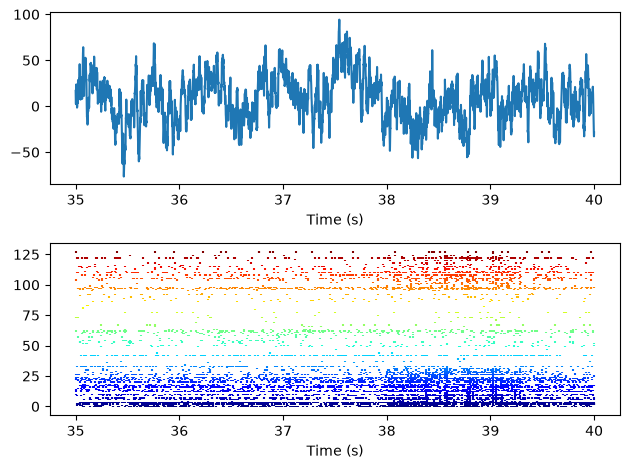

In [7]:
start, end = lfp.t[70000], lfp.t[80000]
win = nap.IntervalSet(start=start, end=end)
print(win)

lfp_win = lfp.get(start, end)
spikes_win = spikes.restrict(win)

fig = plt.figure()
ax1 = fig.add_subplot(2, 1, 1)
ax2 = fig.add_subplot(2, 1, 2)
ax1.plot(lfp_win.t, lfp_win.d[:,42])
ax1.set_xlabel("Time (s)")
colors = plt.cm.jet(np.linspace(0, 1, len(spikes)))
ax2.eventplot([spikes_win[i].t for i in spikes.keys()], colors=colors)
ax2.set_xlabel("Time (s)")
plt.tight_layout()
plt.show()

In [9]:
ev = load_task_events(f"{data_day2_path}/SeqPre_110423_a001.nev", photodiode=data_day2["1:nsx4"][:,3])
print(ev)

{'baseline':   index    start      end
      0    21.51  321.537
shape: (1, 2), time unit: sec., 'task':   index    start      end
      0  321.537  4488.15
shape: (1, 2), time unit: sec., 'blocks': index    start               end                 block
0        321.6034333333333   454.09636666666665  1
1        456.1639666666667   588.2495            2
2        588.2713666666667   719.5245666666667   3
3        721.3391            853.4091666666667   4
4        853.4267666666667   985.0258333333334   5
5        986.6519333333333   1118.3943666666667  6
6        1118.4123666666667  1256.1445           7
...      ...                 ...                 ...
23       3550.7386666666666  3681.2392666666665  24
24       3683.3522666666668  3815.523866666667   25
25       3817.079566666667   3949.375            26
26       3951.2442333333333  4084.712666666667   27
27       4087.0757           4219.1991           28
28       4221.1786           4353.1923           29
29       4355.1780666666

In [20]:
imgs = ev['images']
display(imgs[:5])

  index    start      end    image    block    seq    pos    code_onset  ...
      0  321.716  322            1        1      1      1        321.68  ...
      1  322.317  322.6          2        1      1      2        322.28  ...
      2  322.917  323.2          3        1      1      3        322.88  ...
      3  323.517  323.8          4        1      1      4        323.48  ...
      4  326.784  327.067        5        1      2      1        326.75  ...
shape: (5, 2), time unit: sec.

In [32]:
contexts = {
    "context1": lambda x: (x.block <= 20) & (x.block % 2 == 1),
    "context2": lambda x: (x.block <= 20) & (x.block % 2 == 0)
}

label(imgs, "context", contexts)  # label each image with a new column called "context" according to contexts (defined above)

index    start               end                 image    block    seq    pos    code_onset    context    ...
0        321.7165            322.00039999999996  1        1        1      1      321.68        context1   ...
1        322.31699999999995  322.6004            2        1        1      2      322.28        context1   ...
2        322.917             323.20029999999997  3        1        1      3      322.88        context1   ...
3        323.517             323.8003            4        1        1      4      323.48        context1   ...
4        326.7836            327.0669            5        1        2      1      326.75        context1   ...
5        327.38359999999994  327.6669            6        1        2      2      327.35        context1   ...
6        327.98359999999997  328.26689999999996  7        1        2      3      327.95        context1   ...
...      ...                 ...                 ...      ...      ...    ...    ...           ...        ...
2993     4

In [41]:
context_tuning = nap.compute_response_per_epoch(spikes, split_by(imgs, "context"))

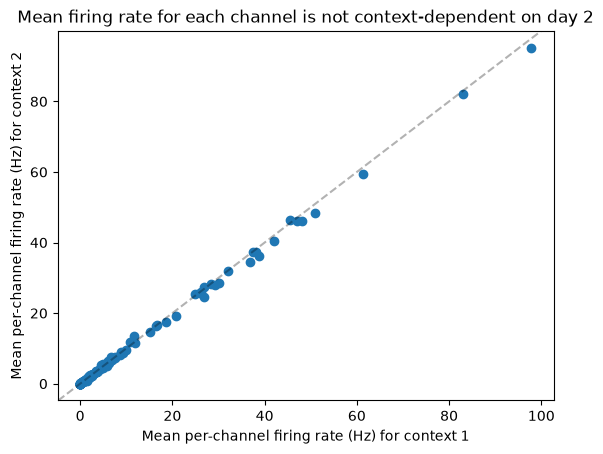

In [53]:
plt.scatter(context_tuning[:,0],context_tuning[:,1])
plt.axline((0, 0), slope=1, color='black', linestyle='--', alpha=.3)
plt.xlabel('Mean per-channel firing rate (Hz) for context 1')
plt.ylabel('Mean per-channel firing rate (Hz) for context 2')
plt.title('Mean firing rate for each channel is not context-dependent on day 2')
plt.savefig(f'{figure_path}/mean_contextdpdt_FR_day2.png')
plt.show()

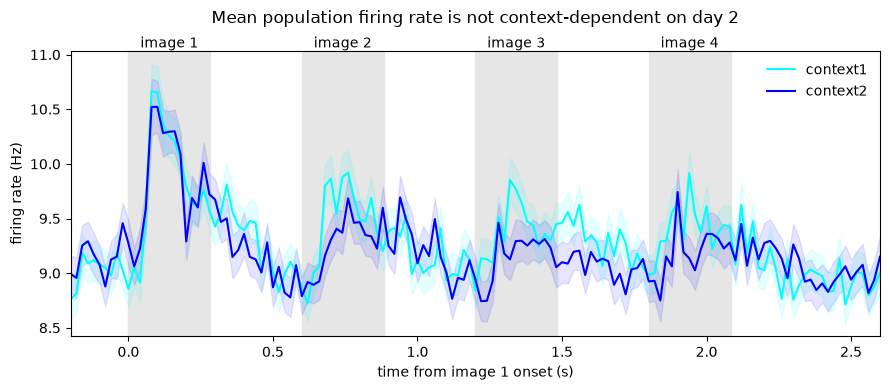

In [64]:
# population PSTH around sequences, split by context
bin_size = 0.02
window = (-0.2, 2.6)  # include data from 200ms before and after each sequence (4 images x 600ms = 2.4s per sequence)

first = imgs[imgs.pos == 1]
counts = spikes.count(bin_size)

fig, ax = plt.subplots(figsize=(9, 4))
colors = ['cyan', 'blue']

for i, ctx in enumerate(["context1", "context2"]):
    onsets = nap.Ts(t=first[first.context == ctx].start)
    p = nap.compute_perievent(counts, onsets, window=window)    # (time, sequences, channels)
    rate = np.nanmean(np.asarray(p), axis=2) / bin_size         # population rate per sequence (Hz)
    m = rate.mean(axis=1)
    sem = rate.std(axis=1) / np.sqrt(rate.shape[1])
    ax.plot(p.t, m, label=ctx, color=colors[i])
    ax.fill_between(p.t, m - sem, m + sem, alpha=0.1, color=colors[i])

# shade each image's on-screen period (photodiode times, median relative to image 1)
for k in range(1, 5):
    on = np.median(imgs[imgs.pos == k].start - first.start)
    off = np.median(imgs[imgs.pos == k].end - first.start)
    ax.axvspan(on, off, color="0.9", zorder=0)
    ax.text((on + off) / 2, 1.0, f"image {k}", transform=ax.get_xaxis_transform(),
            ha="center", va="bottom")

ax.set(xlabel="time from image 1 onset (s)", ylabel="firing rate (Hz)", xlim=window)
ax.legend(frameon=False)
plt.title('Mean population firing rate is not context-dependent on day 2', pad=20)
plt.tight_layout()
plt.savefig(f'{figure_path}/population_contextdpdt_FR_day2')
plt.show()

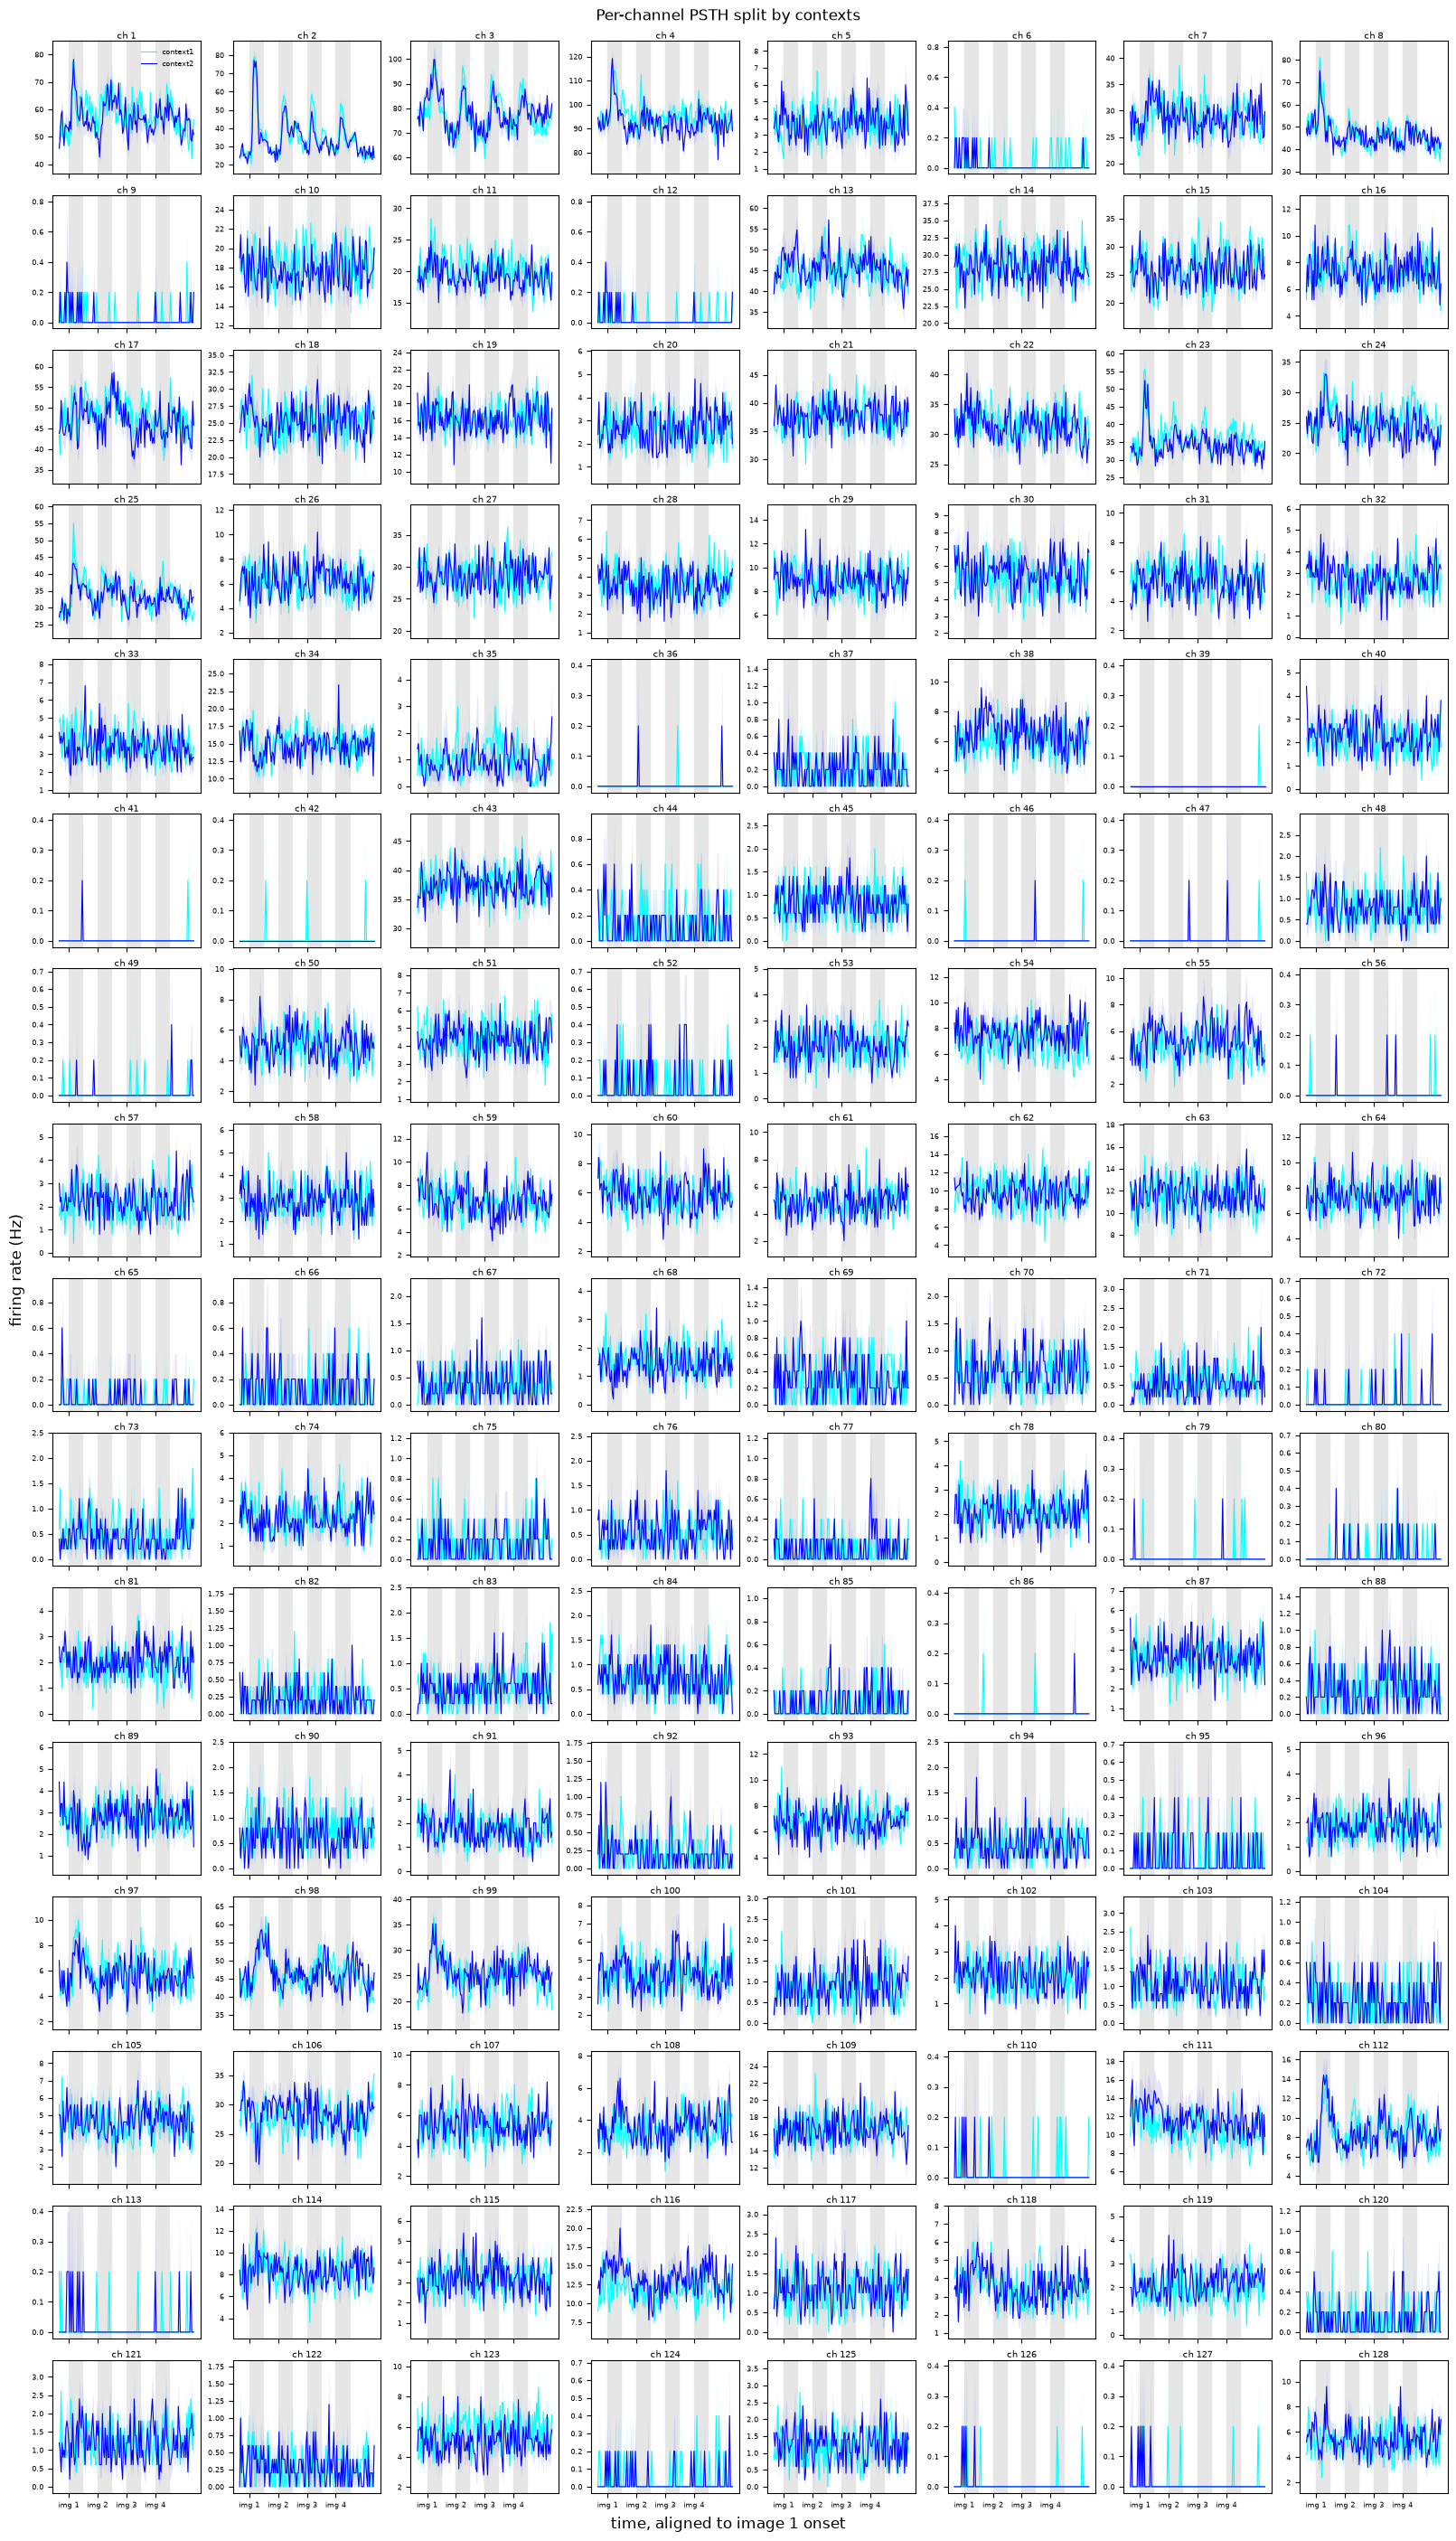

In [65]:
# rate[ctx]: (time, sequences, channels), in Hz — computed once, reused by every subplot
rate = {}
for ctx in contexts:
    p = nap.compute_perievent(counts, nap.Ts(t=first[first.context == ctx].start), window=window)
    rate[ctx] = np.asarray(p) / bin_size
t = p.t

img_on = [np.median(imgs[imgs.pos == k].start - first.start) for k in range(1, 5)]
img_off = [np.median(imgs[imgs.pos == k].end - first.start) for k in range(1, 5)]
ch_ids = np.asarray(spikes.channel_id)

fig, axs = plt.subplots(16, 8, figsize=(16, 28), sharex=True, constrained_layout=True)
for ch, ax in enumerate(axs.flat):
    for on, off in zip(img_on, img_off):
        ax.axvspan(on, off, color="0.9", zorder=0)
    for i, ctx in enumerate(contexts):
        r = rate[ctx][:, :, ch]
        m, sem = r.mean(axis=1), r.std(axis=1) / np.sqrt(r.shape[1])
        ax.plot(t, m, lw=0.8, label=ctx, color=colors[i])
        ax.fill_between(t, m - sem, m + sem, alpha=0.1, lw=0, color=colors[i])
    ax.set_title(f"ch {ch_ids[ch]}", fontsize=7, pad=2)
    ax.tick_params(labelsize=6)

axs[0, 0].legend(fontsize=6, frameon=False)
for ax in axs[-1]:
    ax.set_xticks(img_on, [f"img {k}" for k in range(1, 5)])
fig.supxlabel("time, aligned to image 1 onset")
fig.supylabel("firing rate (Hz)")
fig.suptitle('Per-channel PSTH split by contexts')
plt.savefig(f'{figure_path}/perchannel_contextdpdt_FR_day2')
plt.show()